# Plotting

The displays are the part of an interpretation people actually look at, so the library ships the
standard ones rather than leaving you to build them. They all take a `Well` and return a
matplotlib figure you can save. This is a quick catalog; run the workflow first so there's
something to draw.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
REPO = Path.cwd()
while not (REPO / "src" / "petrophys").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "src"))
WELL = REPO / "src" / "petrophys" / "datasets" / "geolink" / "30_6-5.las"

from petrophys.io import read_las
from petrophys.workflow import run_dynamic_workflow
well = read_las(WELL)
run_dynamic_workflow(well, lithology="clastic");

The **triple combo** is the workhorse field display: gamma ray and caliper, resistivity, and
the density, neutron, and sonic logs:

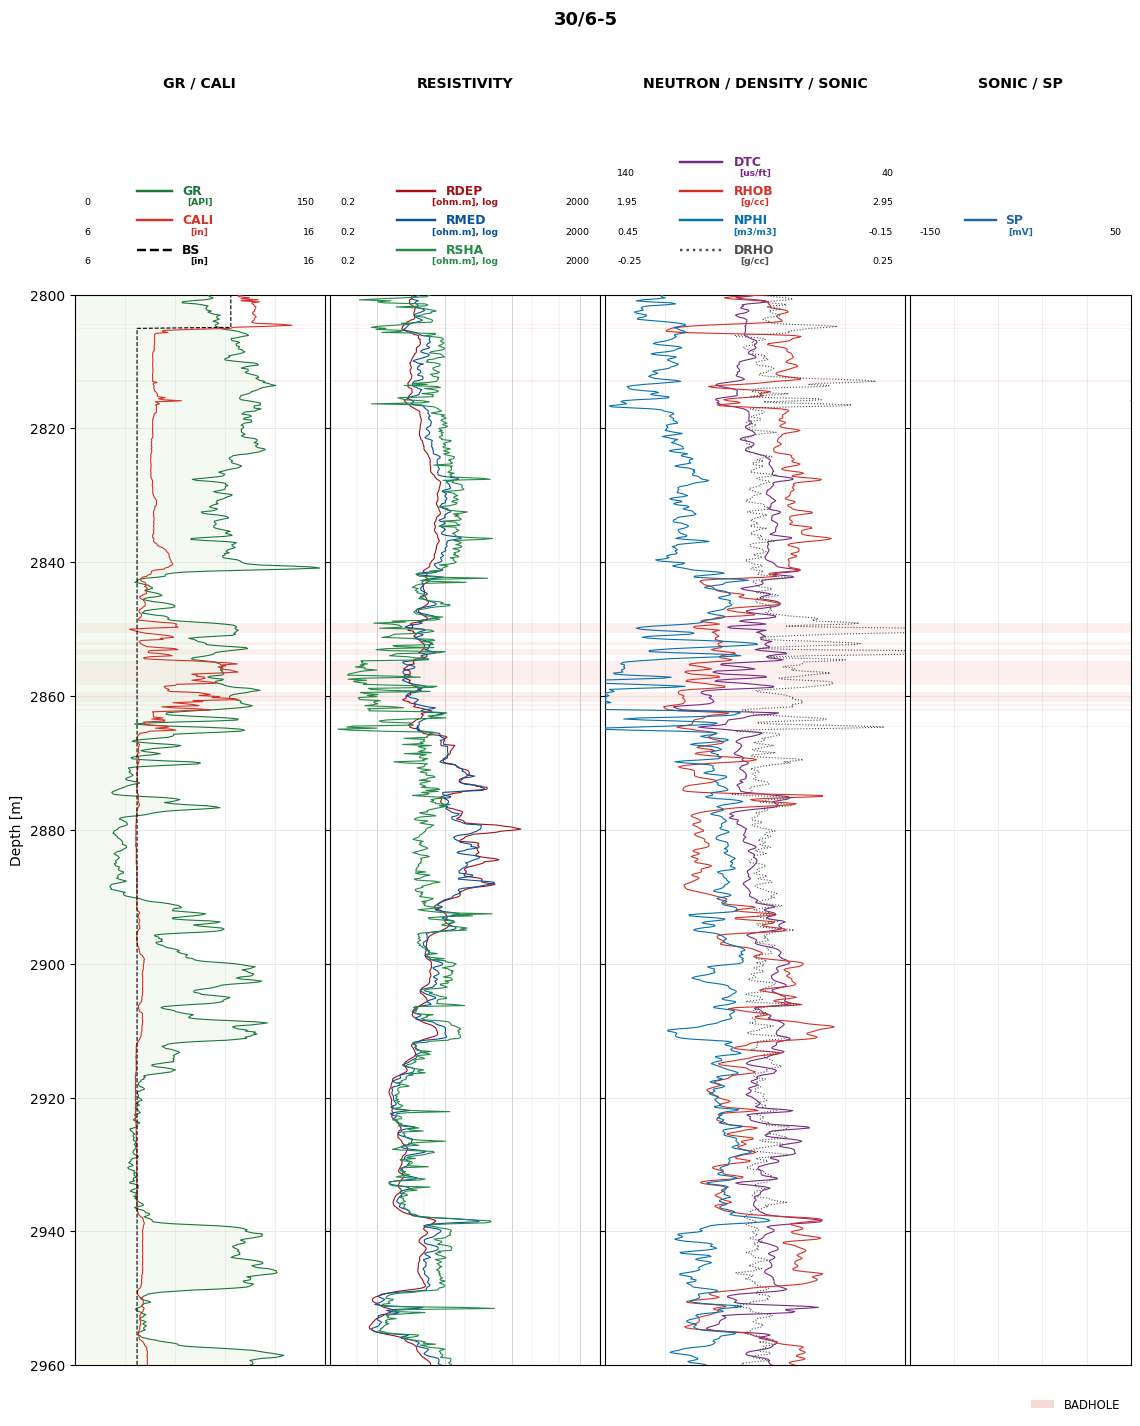

In [2]:
from petrophys.visualization import create_triple_combo
create_triple_combo(well, depth_range=(2800, 2960));

The **neutron-density crossplot** sorts lithology: points fall on the sandstone, limestone, or dolomite line according to matrix, and shift right with shale:

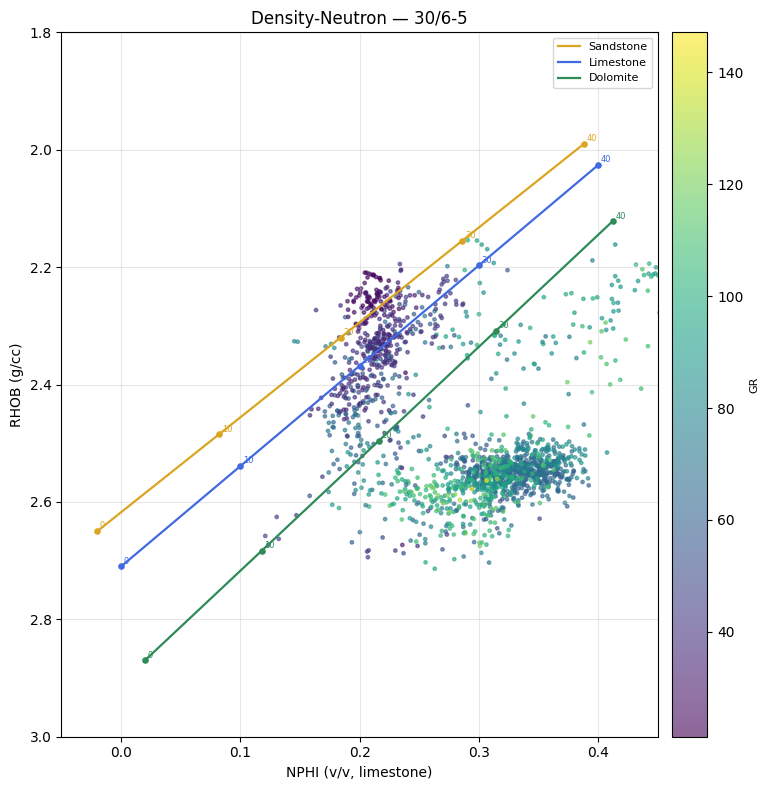

In [3]:
from petrophys.visualization import create_nd_crossplot
create_nd_crossplot(well, color_curve="GR", depth_range=(2700, 2960));

And the **Pickett plot** is the saturation workhorse: resistivity against porosity for reading Rw, m, and the hydrocarbon lift-off:

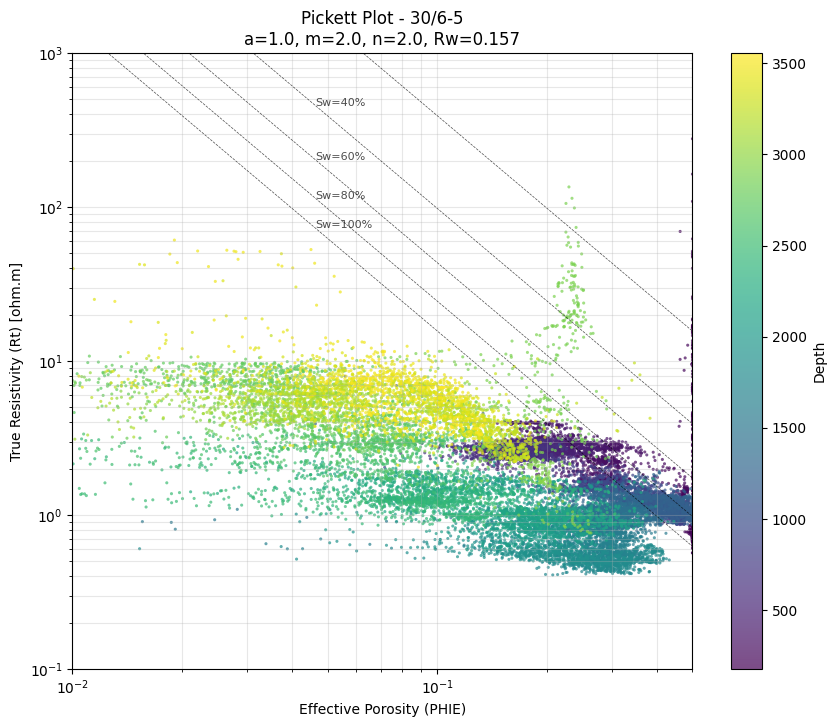

In [4]:
from petrophys.visualization import create_pickett_plot
import numpy as np
create_pickett_plot(well, rw=float(np.nanmedian(well.get("RW").data)), phie_curve="PHIE", rt_curve="RDEP");

There's more where these came from: a template-driven `create_log_viewer` for full custom
displays, M-N and MID crossplots, Buckles and Hingle plots, FMI and NMR panels. Same pattern
throughout: pass the well, get a figure.